# Analyse sweep B&B — figures

Lecture de `results/sweep_bab_0.csv`, génération des figures dans `figures/`.

**Figures produites :**
1. `fig1_temps.pdf` — t_solve et t_bab_pure pour V1LD_fixed et V1CLD_fixed
2. `fig2_node_reduction.pdf` — % réduction noeuds fixed → patience
3. `fig3_fails.pdf` — fails (fixed vs patience) et pct_fails_bound
4. `fig4_more_calls.pdf` — more_calls (fixed vs patience) et pct_ub_tight

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})

FIGURES_DIR = Path(ROOT) / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)

COLORS = {
    'V1LD_fixed':     '#1f77b4',
    'V1CLD_fixed':    '#ff7f0e',
    'V1LD_patience':  '#aec7e8',
    'V1CLD_patience': '#ffbb78',
}
FIXED_MODES    = ['V1LD_fixed', 'V1CLD_fixed']
PATIENCE_MODES = ['V1LD_patience', 'V1CLD_patience']
ALL_MODES      = FIXED_MODES + PATIENCE_MODES
X_VARS   = ['N', 'n', 'm']
X_LABELS = ['N (scénarios)', 'n (items)', 'm (contraintes)']

In [2]:
try:
    ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__vsc_ipynb_file__)))
except NameError:
    ROOT = os.path.dirname(os.getcwd())

df = pd.read_csv(os.path.join(ROOT, 'results/sweep_bab_0.csv'))
print(f'Données : {df.shape[0]} lignes')
print(f'modes : {sorted(df["mode"].unique())}')
print(f'N={sorted(df.N.unique())},  n={sorted(df.n.unique())},  m={sorted(df.m.unique())}')
df.head(4)

Données : 192 lignes
modes : ['V1CLD_fixed', 'V1CLD_patience', 'V1LD_fixed', 'V1LD_patience']
N=[np.int64(50), np.int64(100), np.int64(250), np.int64(500)],  n=[np.int64(5), np.int64(10), np.int64(20)],  m=[np.int64(2), np.int64(5), np.int64(10), np.int64(15)]


,mode,n,m,N,rep,T_root,T_node,patience,patience_tol,statut,...,inc_imp,more_calls,ub_tight,pct_ub_tight,t_solve,t_root_bound,t_bound_total,t_bab_pure,ms_node,t_wall
0,V1LD_fixed,5,2,50,0,200,5,False,NaN,OPTIMAL,...,3,12,10,83.33,0.153,0.005,0.010,0.1,10.232,1.621
1,V1CLD_fixed,5,2,50,0,200,5,False,NaN,OPTIMAL,...,3,12,9,75.00,0.012,0.005,0.011,0.0,0.769,0.185
2,V1LD_patience,5,2,50,0,200,5,True,1.0,OPTIMAL,...,3,10,7,70.00,0.016,0.005,0.016,0.0,1.144,0.080
3,V1CLD_patience,5,2,50,0,200,5,True,1.0,OPTIMAL,...,3,10,7,70.00,0.017,0.005,0.017,0.0,1.230,0.068


In [3]:
def agg(df_sub, x_var, y_col):
    """Moyenne de y_col par (mode, x_var), en agrégeant sur les autres dims."""
    return df_sub.groupby(['mode', x_var])[y_col].mean().reset_index()


def plot_lines(ax, df, mode_list, x_var, y_col, ylabel=None, title=None):
    """Trace une ligne par mode sur ax."""
    for mode in mode_list:
        sub = agg(df[df['mode'] == mode], x_var, y_col).sort_values(x_var)
        ax.plot(sub[x_var], sub[y_col], 'o-', color=COLORS[mode],
                label=mode.replace('_', ' '))
    ax.set_xlabel(x_var)
    if ylabel:
        ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)


def save_fig(fig, name):
    fig.savefig(FIGURES_DIR / f'{name}.pdf')
    fig.savefig(FIGURES_DIR / f'{name}.png')
    print(f'  → figures/{name}.pdf / .png')

## 1. Temps d'exécution — V1LD_fixed et V1CLD_fixed

- **t_solve** : temps total de résolution
- **t_bab_pure** : temps pur du B&B (hors calcul des bornes)

  → figures/fig1_temps.pdf / .png


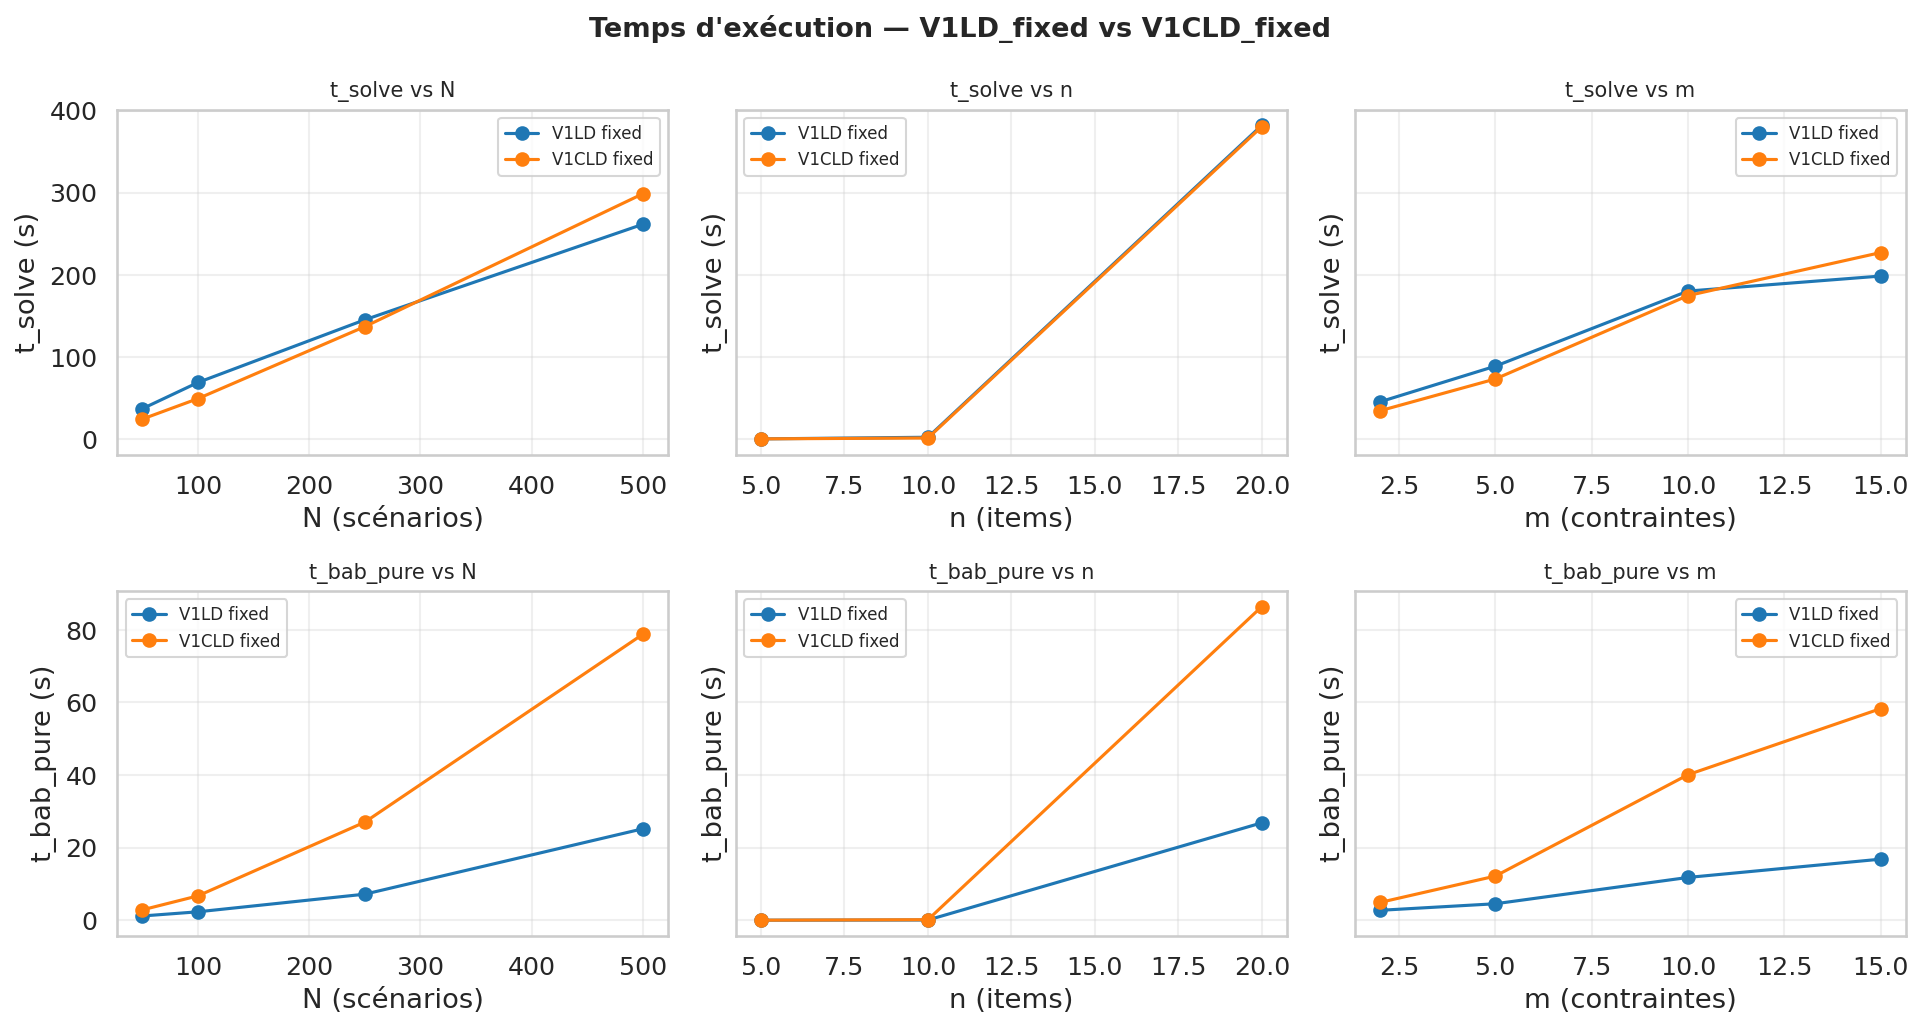

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey='row')

for j, (xv, xl) in enumerate(zip(X_VARS, X_LABELS)):
    plot_lines(axes[0, j], df[df['mode'].isin(FIXED_MODES)],
               FIXED_MODES, xv, 't_solve',
               ylabel='t_solve (s)', title=f't_solve vs {xv}')
    axes[0, j].set_xlabel(xl)

    plot_lines(axes[1, j], df[df['mode'].isin(FIXED_MODES)],
               FIXED_MODES, xv, 't_bab_pure',
               ylabel='t_bab_pure (s)', title=f't_bab_pure vs {xv}')
    axes[1, j].set_xlabel(xl)

fig.suptitle("Temps d'exécution — V1LD_fixed vs V1CLD_fixed",
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig(fig, 'fig1_temps')
plt.show()

## 2. Réduction de noeuds — fixed → patience

Pourcentage de réduction du nombre de noeuds B&B :
$$\text{réduction (\%)} = \frac{\text{nodes}_{\text{fixed}} - \text{nodes}_{\text{patience}}}{\text{nodes}_{\text{fixed}}} \times 100$$

  → figures/fig2_node_reduction.pdf / .png


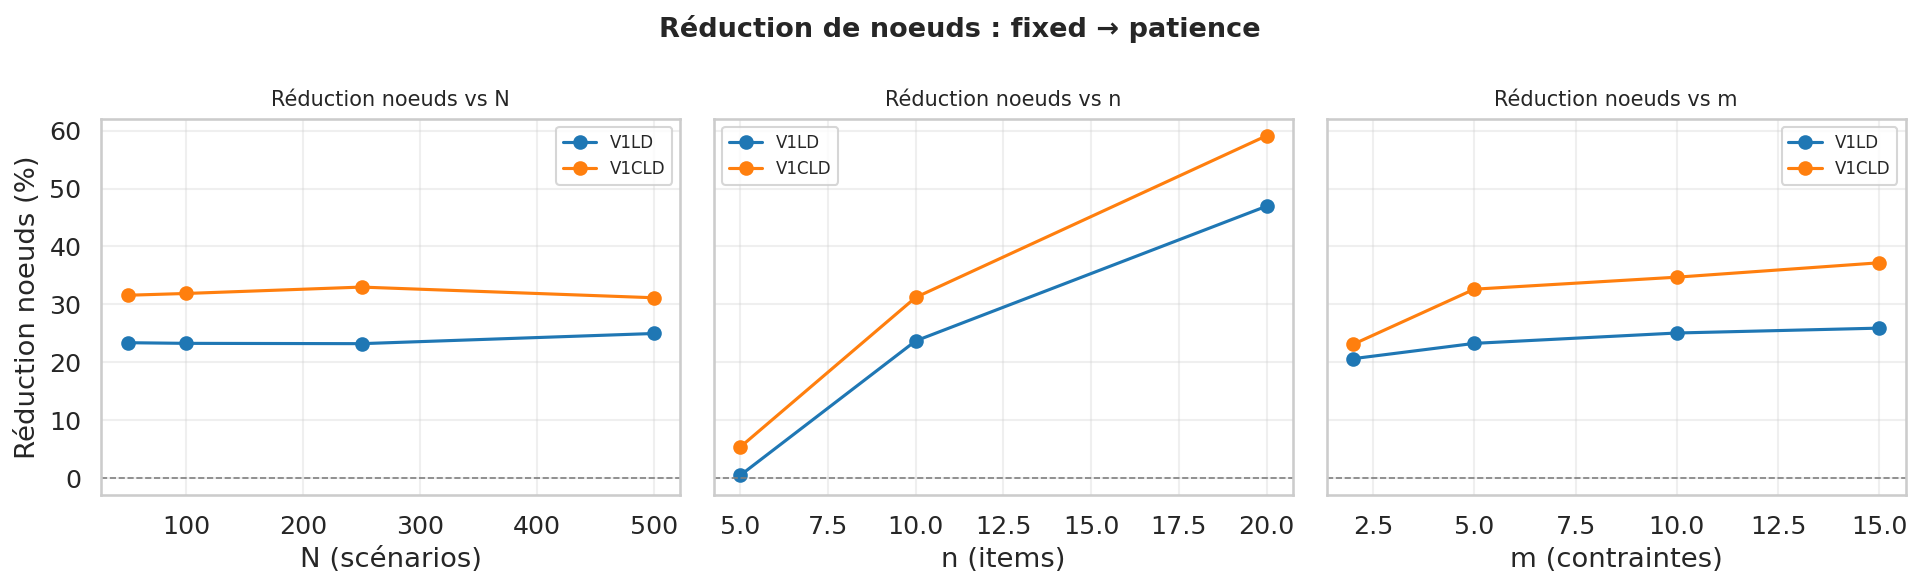

In [5]:
def compute_node_reduction(df, mode_fixed, mode_patience):
    f = (df[df['mode'] == mode_fixed][['n', 'm', 'N', 'nodes']]
         .rename(columns={'nodes': 'nodes_f'}))
    p = (df[df['mode'] == mode_patience][['n', 'm', 'N', 'nodes']]
         .rename(columns={'nodes': 'nodes_p'}))
    merged = f.merge(p, on=['n', 'm', 'N'])
    merged['reduction_pct'] = ((merged['nodes_f'] - merged['nodes_p'])
                               / merged['nodes_f'] * 100)
    merged['pair'] = mode_fixed.replace('_fixed', '')
    return merged

df_red = pd.concat([
    compute_node_reduction(df, 'V1LD_fixed',  'V1LD_patience'),
    compute_node_reduction(df, 'V1CLD_fixed', 'V1CLD_patience'),
])

PAIR_COLORS = {'V1LD': '#1f77b4', 'V1CLD': '#ff7f0e'}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

for j, (xv, xl) in enumerate(zip(X_VARS, X_LABELS)):
    for pair, color in PAIR_COLORS.items():
        sub = (df_red[df_red.pair == pair]
               .groupby(xv)['reduction_pct'].mean()
               .reset_index()
               .sort_values(xv))
        axes[j].plot(sub[xv], sub['reduction_pct'], 'o-',
                     color=color, label=pair)
    axes[j].axhline(0, color='gray', linestyle='--', linewidth=0.8)
    axes[j].set_xlabel(xl)
    if j == 0:
        axes[j].set_ylabel('Réduction noeuds (%)')
    axes[j].set_title(f'Réduction noeuds vs {xv}', fontsize=10)
    axes[j].legend(fontsize=8)
    axes[j].grid(True, alpha=0.3)

fig.suptitle('Réduction de noeuds : fixed → patience',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig(fig, 'fig2_node_reduction')
plt.show()

## 3. Fails — fixed vs patience et pct_fails_bound

- **Rows 1–2** : nombre de fails B&B pour chaque paire (V1LD, V1CLD)
- **Row 3** : `pct_fails_bound` = fraction des fails attribuable à la borne (vs CP)

  → figures/fig3_fails.pdf / .png


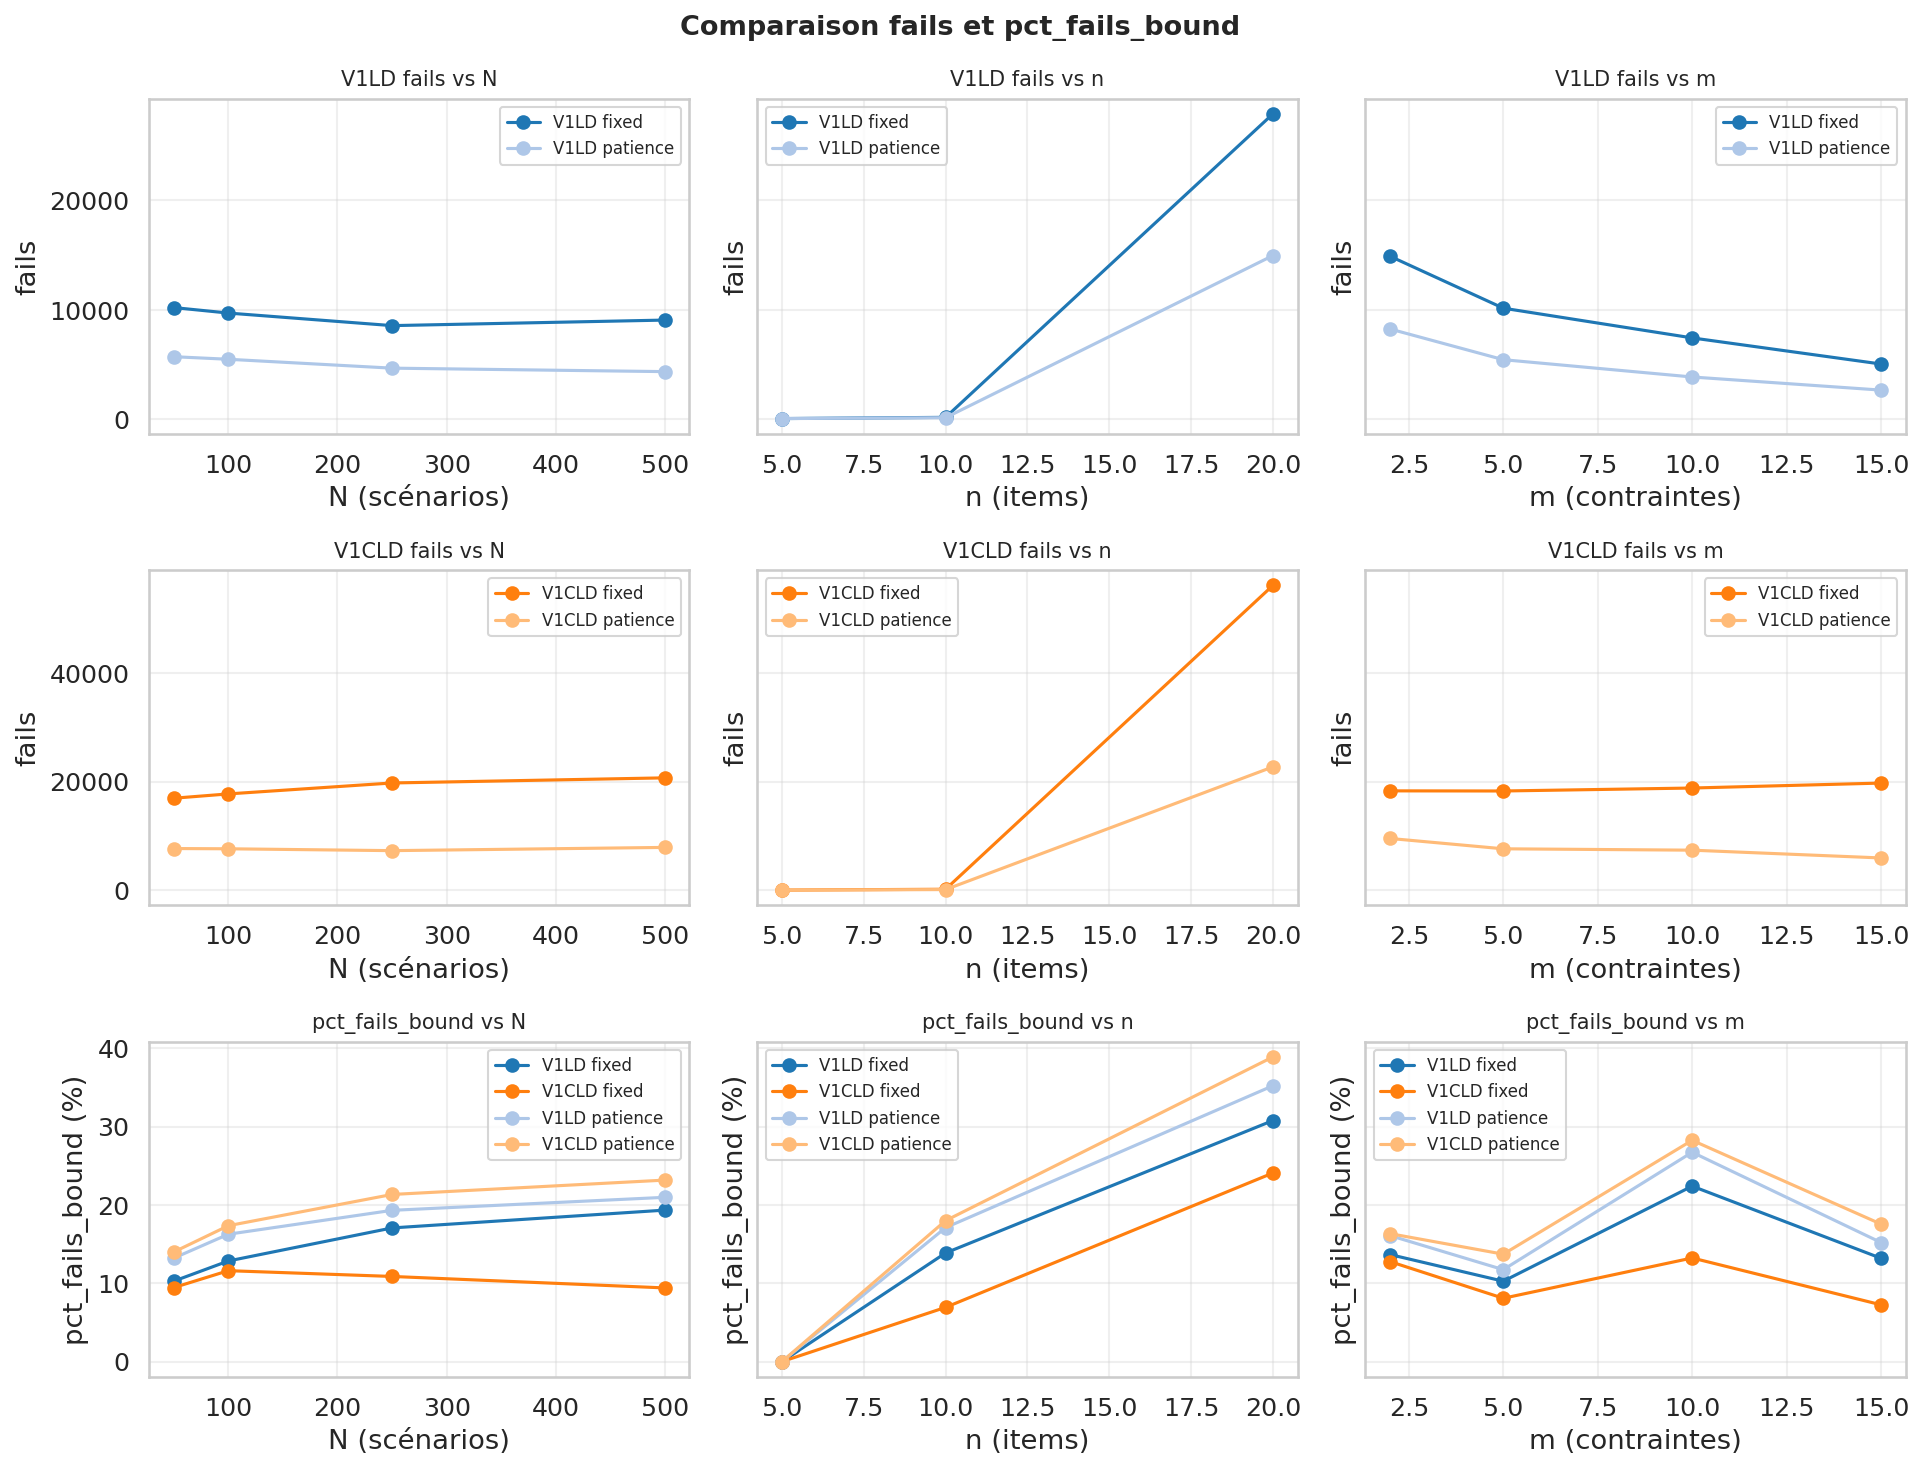

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharey='row')

for j, (xv, xl) in enumerate(zip(X_VARS, X_LABELS)):
    plot_lines(axes[0, j],
               df[df['mode'].isin(['V1LD_fixed', 'V1LD_patience'])],
               ['V1LD_fixed', 'V1LD_patience'],
               xv, 'fails', ylabel='fails', title=f'V1LD fails vs {xv}')
    axes[0, j].set_xlabel(xl)

    plot_lines(axes[1, j],
               df[df['mode'].isin(['V1CLD_fixed', 'V1CLD_patience'])],
               ['V1CLD_fixed', 'V1CLD_patience'],
               xv, 'fails', ylabel='fails', title=f'V1CLD fails vs {xv}')
    axes[1, j].set_xlabel(xl)

    plot_lines(axes[2, j], df, ALL_MODES,
               xv, 'pct_fails_bound',
               ylabel='pct_fails_bound (%)', title=f'pct_fails_bound vs {xv}')
    axes[2, j].set_xlabel(xl)

fig.suptitle('Comparaison fails et pct_fails_bound',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig(fig, 'fig3_fails')
plt.show()

## 4. More calls — fixed vs patience et pct_ub_tight

- **Rows 1–2** : nombre d'appels supplémentaires au solveur de borne (`more_calls`)
- **Row 3** : `pct_ub_tight` = % de ces appels ayant produit une borne UB tight

  → figures/fig4_more_calls.pdf / .png


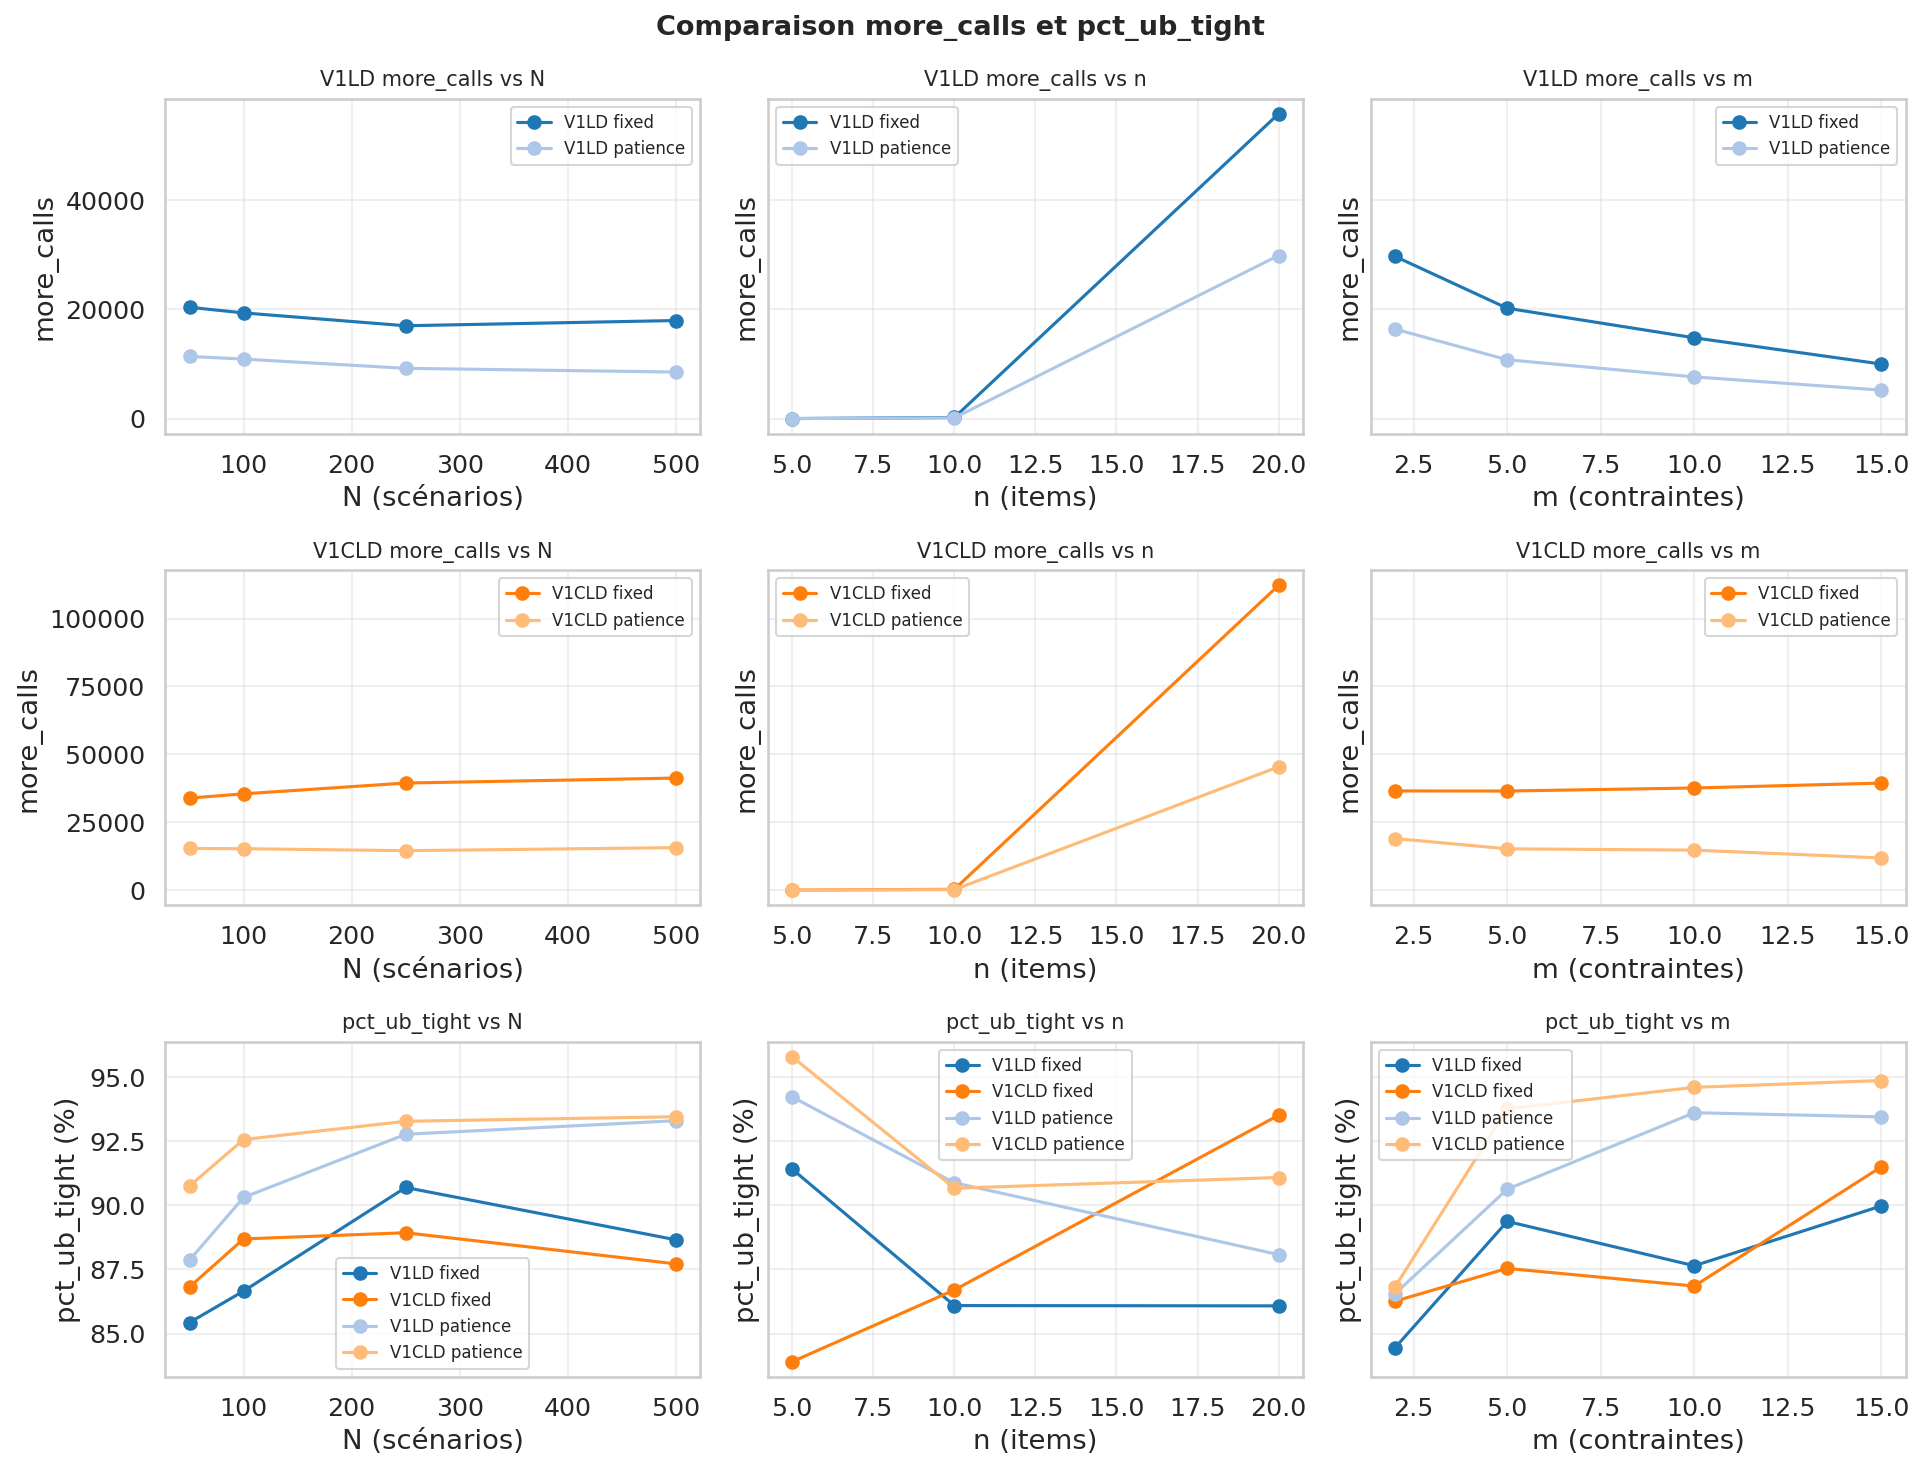

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharey='row')

for j, (xv, xl) in enumerate(zip(X_VARS, X_LABELS)):
    plot_lines(axes[0, j],
               df[df['mode'].isin(['V1LD_fixed', 'V1LD_patience'])],
               ['V1LD_fixed', 'V1LD_patience'],
               xv, 'more_calls', ylabel='more_calls', title=f'V1LD more_calls vs {xv}')
    axes[0, j].set_xlabel(xl)

    plot_lines(axes[1, j],
               df[df['mode'].isin(['V1CLD_fixed', 'V1CLD_patience'])],
               ['V1CLD_fixed', 'V1CLD_patience'],
               xv, 'more_calls', ylabel='more_calls', title=f'V1CLD more_calls vs {xv}')
    axes[1, j].set_xlabel(xl)

    plot_lines(axes[2, j], df, ALL_MODES,
               xv, 'pct_ub_tight',
               ylabel='pct_ub_tight (%)', title=f'pct_ub_tight vs {xv}')
    axes[2, j].set_xlabel(xl)

fig.suptitle('Comparaison more_calls et pct_ub_tight',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig(fig, 'fig4_more_calls')
plt.show()

---
## 5. Tableaux comparatifs — Gecode base vs V1LD vs V1CLD

Pour chaque combinaison **(n, m, N)**, comparaison des 5 méthodes sur :
`nodes`, `depth`, `fails`, `pct_fails_bound`, `t_solve`, `t_bab_pure`.

- **Bleu** : méthode avec le moins de nœuds
- **Orange** : méthode avec le `t_bab_pure` le plus bas (NaN ignoré)

> Note : le sweep contient **n ∈ {5, 10, 20}** (n=15 absent des données).
> Paramètres affichés : m ∈ {5, 10, 15}, N ∈ {100, 250, 500}.

In [ ]:
# ── Chargement des deux datasets ─────────────────────────────────────────────
df_bab  = pd.read_csv(os.path.join(ROOT, 'results/sweep_bab_0 copy.csv'))
df_base = pd.read_csv(os.path.join(ROOT, 'results/sweep_bab_base.csv'))
df_all  = pd.concat([df_bab, df_base], ignore_index=True)

MODE_ORDER = ['Gecode_base', 'V1LD_fixed', 'V1CLD_fixed', 'V1LD_patience', 'V1CLD_patience']
MODE_LABELS = {
    'Gecode_base':    'Gecode base',
    'V1LD_fixed':     'V1LD',
    'V1CLD_fixed':    'V1CLD',
    'V1LD_patience':  'V1LD patience',
    'V1CLD_patience': 'V1CLD patience',
}
METRICS   = ['nodes', 'depth', 'fails', 'pct_fails_bound', 't_solve', 't_bab_pure']
N_CMP     = [5, 10, 20]
M_CMP     = [5, 10, 15]
S_CMP     = [100, 250, 500]

print(f'Lignes totales : {df_all.shape[0]}')
print(f'Modes : {sorted(df_all["mode"].unique())}')

In [ ]:
import math
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from IPython.display import display, Image, HTML

COLS = ['nodes', 'depth', 'fails', 'pct_fails_bound', 't_solve', 't_bab_pure']
HDR  = ['m', 'N', 'méthode'] + COLS

FMT = {
    'nodes':           lambda v: f'{int(v)}',
    'depth':           lambda v: f'{int(v)}',
    'fails':           lambda v: f'{int(v)}',
    'pct_fails_bound': lambda v: f'{v:.1f}',
    't_solve':         lambda v: f'{v:.3f}',
    't_bab_pure':      lambda v: f'{v:.4f}',
}

C_NODES  = '#cfe2f3'   # bleu  — min nodes
C_TSOLVE = '#c6efce'   # vert  — min t_solve
C_TBAB   = '#fce8b2'   # orange — min t_bab_pure
C_HDR    = '#cccccc'
C_MN_BG  = '#ebebeb'   # fond colonne m/N
C_GRP_A  = '#f8f8f8'   # fond groupe pair
C_GRP_B  = '#ffffff'   # fond groupe impair

TABLES_DIR = Path(ROOT) / 'results' / 'tables'
TABLES_DIR.mkdir(parents=True, exist_ok=True)


def save_table_image(n_val):
    texts  = []   # [row][col] strings
    colors = []   # [row][col] background hex
    bold   = []   # [row][col] bool

    grp_idx = 0
    for N_val in S_CMP:
        for m_val in M_CMP:
            sub = df_all[(df_all.n == n_val) & (df_all.m == m_val) & (df_all.N == N_val)]
            group = []
            for mode in MODE_ORDER:
                r = sub[sub['mode'] == mode]
                vals = ({col: r.iloc[0][col] for col in COLS} if not r.empty
                        else {col: float('nan') for col in COLS})
                group.append({'label': MODE_LABELS[mode], **vals})

            def grp_min(col):
                cands = [(i, row[col]) for i, row in enumerate(group) if not math.isnan(row[col])]
                return min(cands, key=lambda x: x[1])[0] if cands else None

            min_nodes  = grp_min('nodes')
            min_tsolve = grp_min('t_solve')
            min_tbab   = grp_min('t_bab_pure')
            bg_grp     = C_GRP_A if grp_idx % 2 == 0 else C_GRP_B

            for i, row in enumerate(group):
                # ── Textes ────────────────────────────────────────────────
                txt_mn = [str(m_val) if i == 0 else '',
                          str(N_val) if i == 0 else '']
                txt_vals = ['—' if math.isnan(row[col]) else FMT[col](row[col])
                            for col in COLS]
                texts.append(txt_mn + [row['label']] + txt_vals)

                # ── Couleurs de fond ──────────────────────────────────────
                row_col = [C_MN_BG, C_MN_BG, bg_grp]  # m, N, méthode
                for col in COLS:
                    c = bg_grp
                    if col == 'nodes'      and i == min_nodes:  c = C_NODES
                    if col == 't_solve'    and i == min_tsolve: c = C_TSOLVE
                    if col == 't_bab_pure' and i == min_tbab:   c = C_TBAB
                    row_col.append(c)
                colors.append(row_col)

                # ── Gras ─────────────────────────────────────────────────
                row_bold = [False, False, False]
                for j, col in enumerate(COLS):
                    b = ((col == 'nodes'      and i == min_nodes) or
                         (col == 't_solve'    and i == min_tsolve) or
                         (col == 't_bab_pure' and i == min_tbab))
                    row_bold.append(b)
                bold.append(row_bold)

            grp_idx += 1

    n_rows = len(texts)
    n_cols = len(HDR)

    # ── Figure ────────────────────────────────────────────────────────────
    row_h   = 0.28          # hauteur par ligne (pouces)
    fig_h   = row_h * (n_rows + 2) + 1.2
    fig, ax = plt.subplots(figsize=(19, fig_h))
    ax.axis('off')

    tbl = ax.table(
        cellText   = texts,
        cellColours= colors,
        colLabels  = HDR,
        colColours = [C_HDR] * n_cols,
        cellLoc    = 'center',
        loc        = 'center',
        bbox       = [0, 0, 1, 1],
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)

    # En-tête : gras
    for j in range(n_cols):
        tbl[0, j].set_text_props(fontweight='bold', ha='center')

    # Largeurs de colonnes relatives
    col_widths = [0.04, 0.05, 0.13, 0.10, 0.07, 0.09, 0.12, 0.10, 0.10]
    total_w = sum(col_widths)
    col_widths = [w / total_w for w in col_widths]
    for j, w in enumerate(col_widths):
        for i in range(n_rows + 1):
            tbl[i, j].set_width(w)

    # Alignement et gras par cellule
    for i in range(n_rows):
        tbl[i+1, 0].set_text_props(ha='center', fontweight='bold')
        tbl[i+1, 1].set_text_props(ha='center', fontweight='bold')
        tbl[i+1, 2].set_text_props(ha='left')
        for j in range(3, n_cols):
            fw = 'bold' if bold[i][j] else 'normal'
            tbl[i+1, j].set_text_props(ha='right', fontweight=fw)

    ax.set_title(f'n = {n_val}', fontsize=13, fontweight='bold', pad=6, loc='left')

    # Légende
    handles = [
        mpatches.Patch(color=C_NODES,  label='min nodes'),
        mpatches.Patch(color=C_TSOLVE, label='min t_solve'),
        mpatches.Patch(color=C_TBAB,   label='min t_bab_pure'),
    ]
    ax.legend(handles=handles, loc='upper right', fontsize=8,
              framealpha=0.9, edgecolor='#aaa')

    plt.tight_layout(pad=0.3)

    out_png = TABLES_DIR / f'table_n{n_val}.png'
    out_pdf = TABLES_DIR / f'table_n{n_val}.pdf'
    fig.savefig(out_png, dpi=180, bbox_inches='tight')
    fig.savefig(out_pdf, bbox_inches='tight')
    plt.close(fig)
    return out_png


def display_section(n_val):
    out_png = save_table_image(n_val)
    display(Image(str(out_png)))
    display(HTML(f'<p style="font-size:11px;color:#666">'
                 f'PNG : <code>{out_png}</code> &nbsp;|&nbsp; '
                 f'PDF : <code>{str(out_png).replace(".png",".pdf")}</code></p>'))


In [ ]:
display_section(5)

In [ ]:
display_section(10)

In [ ]:
display_section(20)